# E97: Can a locator name the part a fine-tune's gain runs through, and pass a known answer?

**The answer.** Only one read passed the known answer. Setting a head to the original model's average re-found the copying head on all three copy fine-tunes and spared the lookup fine-tune. Every read that patches the original model's outputs back in, whole parts or single connections, put the last MLP first on both tasks. Those reads show where the gain enters the output, not where it is made. On lowercase, a pair of heads clears the filed rule, but the original model needs that pair too.

*Status: provisional, no independent check. A new circuit built from old parts still reads as reuse, on every claim below that names a part. One of E97's two amendments is spent; a literature review is running.*


## What we were trying to test

`GOALS.md` asks whether post-training teaches new capabilities or strengthens existing ones. The project's definition gives a fine-tune the label "reuses C" only through a located mechanism. That is a part of the model whose removal takes the fine-tune's gain and spares a control task. baseline-lead's reuse table needs that part for each saved 67M fine-tune, or a plain "not found" at a stated grain. E96 showed one locator that works on copying. This experiment asked for nominators that scale, checked against answers we know.

**States and the gain.** A state is a saved fine-tuned copy of the 67M model, and W₀ is the original. The gain $G$ is the state's mean log-odds of the target against all other tokens, minus W₀'s on the same reads. The parts are the 24 attention heads and the 4 block MLPs.

**Three part reads, each a share of $G$ between 0 and 1.**

- *Removal* sets the part's output to W₀'s average over the task's own windows, in the state. Its share is the state's own fall over $G$. W₀'s fall with the same part off is printed beside it and never subtracted.
- *Carry* gives the part, in the state, the output W₀ produces on the same input. W₀ is never moved, so W₀'s own response cannot enter.
- *Write* reverts one weight matrix's update at a time, and all of them at once, which must give back W₀ exactly.

**The edge read, added by the amendment.** An edge is one part's output feeding one later part's input, or the output layer: 927 in all. The *gain path* patches W₀'s value onto one edge at a time in the state. A part's edge into the output layer is its direct write, the piece carry cannot separate from what later parts pass on. A *circuit* is the smallest set of edges that keeps 0.85 of a model's clean-minus-corrupted gap on a pair of inputs, as in Hanna et al. 2024. *Cross-faithfulness* runs the state with every edge outside W₀'s copying circuit patched, and reports the share of its own gap it keeps.

**Known answers, run first.** Two planted edits, one into block 3's MLP and one into block 1's, give exact answers that rest on no earlier fine-tune. Then E62's copy fine-tunes, three seeds, where head (2,4) is known to carry copying, against lookup fine-tunes on the same windows, which should not use it. The located rule asks three things of every seed. The task's fall is at least $a = 0.55$ of its gain, and the control's fall at most 0.2 of its own. The task's fall is also at least twice the control's, in nats. The bar $a$ was read from the weakest copy seed before any other task ran. Last, E53's lowercase fine-tunes against a word cipher, two seeds, on whole rows.


In [1]:
from pathlib import Path

from IPython.display import Image, display

FIG = Path("../experiments/locator_table/figures")


## What we expected, and why

The planted edits should read exactly: the whole gain at the edited MLP, nothing upstream, and only a small share passed on to later parts. That small share is the inheritance floor, the most carry can credit a part that merely passes a change along.

On copy, removal of (2,4) should take 0.56 to 0.65 of the gain, as E96 read, and leave the lookup untouched. We leaned that carry would also put (2,4) first, since carry cannot see W₀'s response. The plan's tree said: if carry misses (2,4), carry reads propagation, and the one amendment falls back to a direct-effect read. The amendment's lean was that the edge from (2,4) to the output would top the gain path on copy. It also leaned that W₀'s copying circuit would keep at least half of the copy states' gap and at most 0.2 of the lookup states'.

On lowercase we leaned "not found at head grain", because E96 found no head near the bar. The question was whether carry and write put the gain in the block MLPs.


## What we observed

### Do the reads find an edit we planted ourselves?


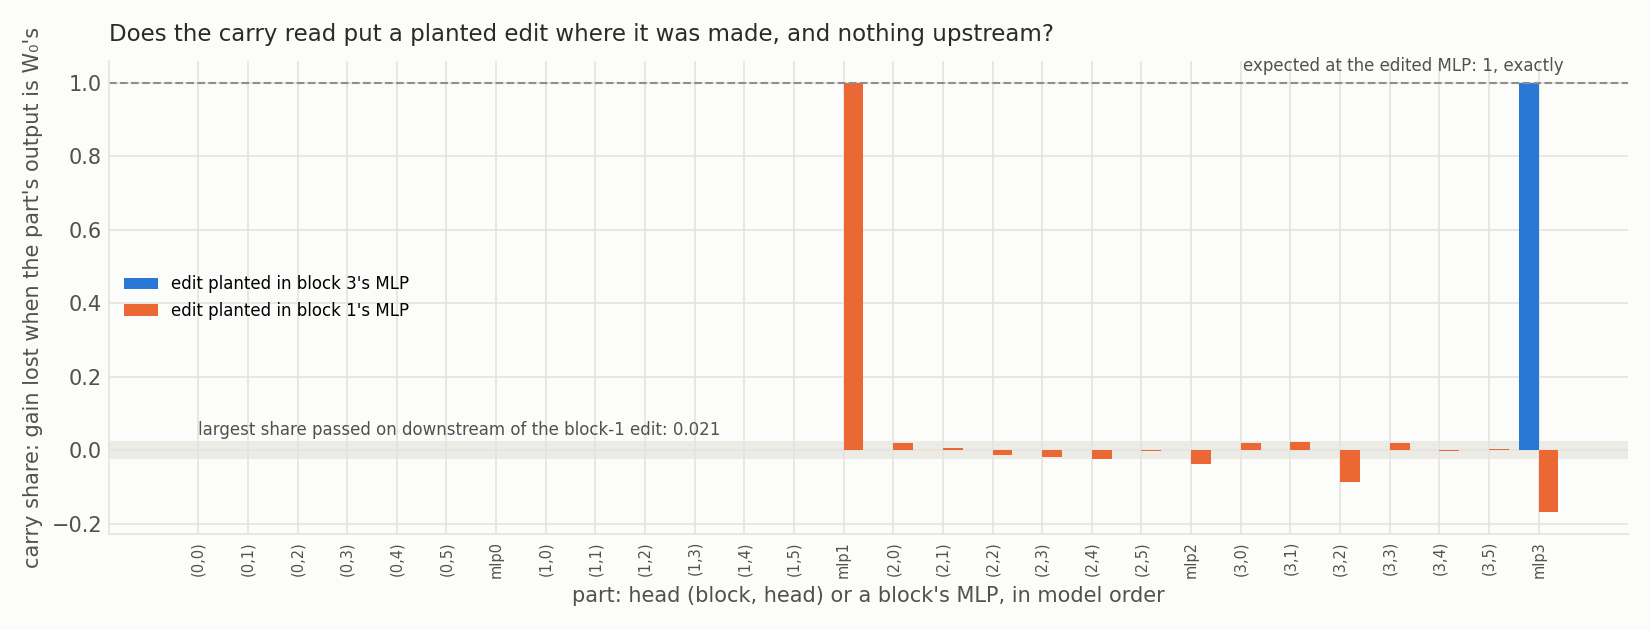

In [2]:
display(Image(FIG / "plants.png", width=950))


**Reading it.** Yes, exactly. The edit planted in block 3's MLP reads 1 at that MLP and 0 on every other part, and the write read reverts the edited matrix for the whole gain. The edit in block 1's MLP also reads 1 where it was made and 0 upstream. Downstream parts pass on at most 0.021 of its gain, which is the inheritance floor. The edge read reproduced the plain model and the fully patched model within a measured floating-point floor of about 3e-5 nats. All gains re-read their stored values within 0.001.


### Which read names the copying head and spares the lookup?


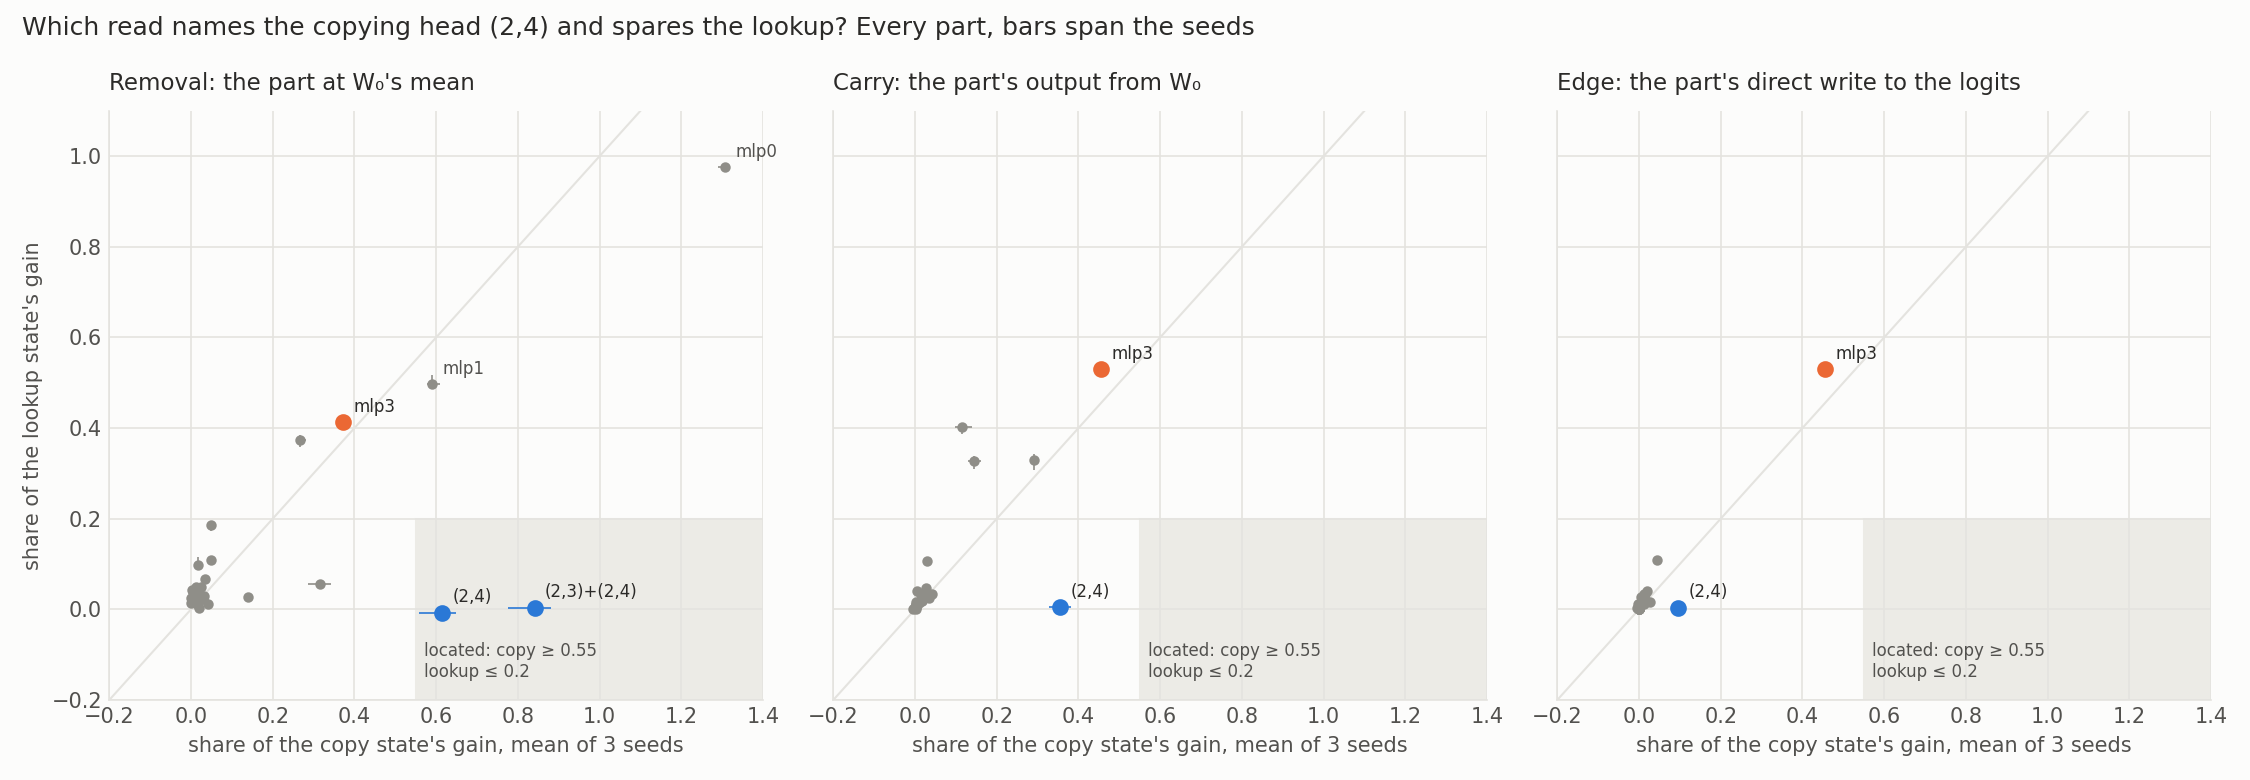

In [3]:
display(Image(FIG / "copy_lookup.png", width=1000))


**Reading it.** Only removal does. It takes 0.56 to 0.65 of the copy gain at (2,4) and leaves the lookup within 0.01, so (2,4) is located, and the pair (2,3)+(2,4) takes 0.78 to 0.88. Carry puts block 3's MLP first on every seed of both tasks, at about 0.45 of the copy gain and 0.53 of the lookup gain. The edge read gives the same order: block 3's MLP writes 0.44 to 0.53 of the gain directly into the output, while (2,4) writes only 0.08 to 0.11. Most of what (2,4) adds reaches the output through the MLPs after it. A read that patches outputs in credits the last part that hands the gain over, whatever the task. Reverting one matrix at a time takes at most 0.04 of the copy gain, while all of them together remove all of it, so the update works jointly.


### Why did the edge run stop?


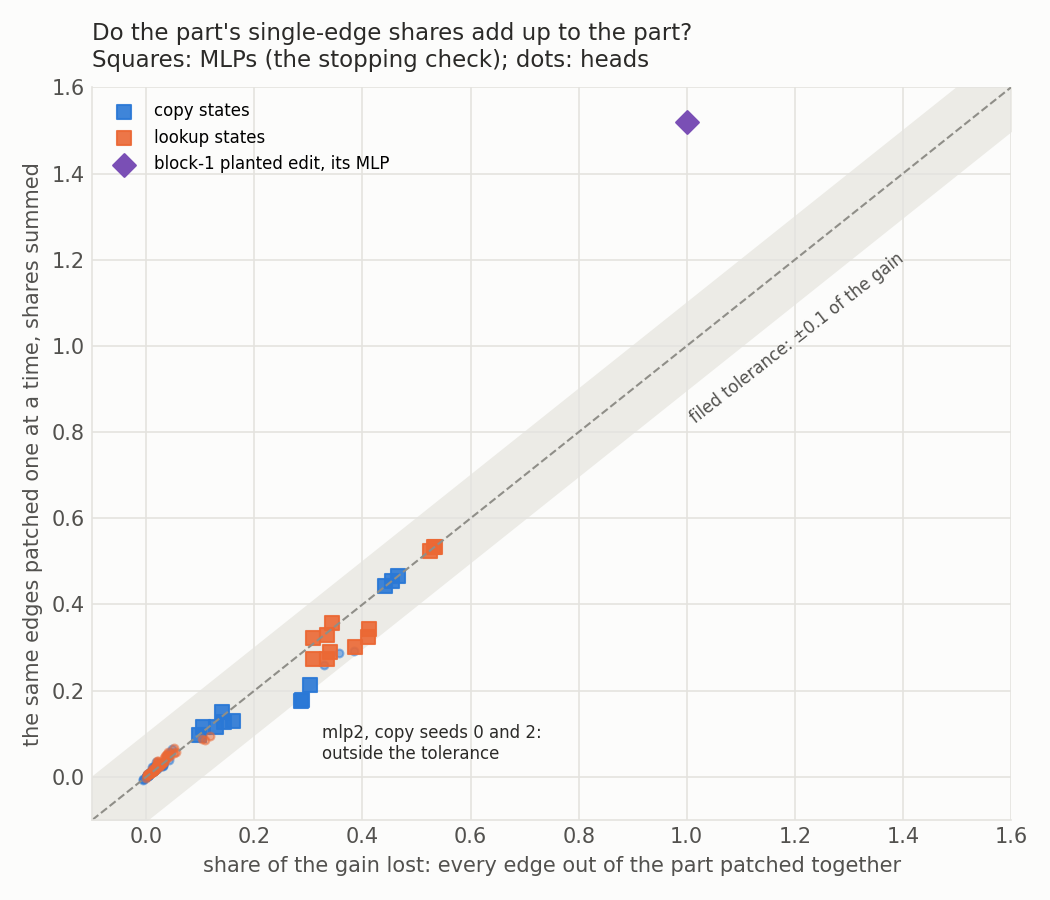

In [4]:
display(Image(FIG / "additivity.png", width=700))


**Reading it.** Single-edge shares do not add up to the part, and the check that expected them to was mis-specified. Patching all of an MLP's edges together reproduces E97's carry read to within 1e-4 on all six states, so the code is right. Summing the same edges one at a time misses block 2's MLP by 0.11 on two copy seeds, just past the filed 0.10. The tolerance came from E96's check of integration steps, which is a different question from whether edges add. The planted edit shows non-additivity by construction: its MLP's single edges sum to 1.52 of the gain against exactly 1 together. The edge readings were saved before the stop, and the tree's branch is decided by them.


### Does W₀'s copying circuit tell the copy fine-tune from the lookup?


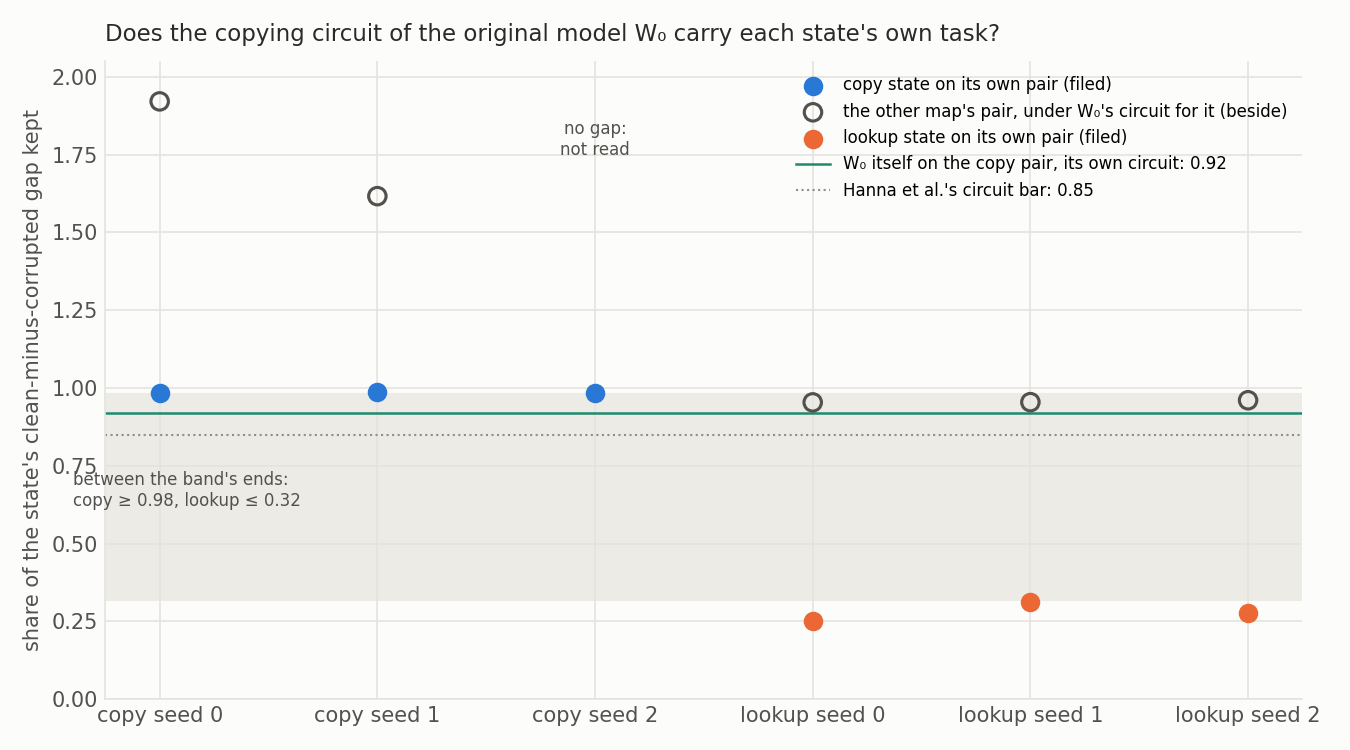

In [5]:
display(Image(FIG / "cross_faith.png", width=900))


**Reading it.** By the filed rule it does, but mostly by construction. Each copy state keeps 0.98 of its gap under W₀'s copying circuit, and each lookup state keeps 0.25 to 0.31. So the filed band, 0.98 against 0.32, separates them. The job stopped before computing it; the rule was applied by hand to the saved numbers. But the copy states are read on the very pair W₀'s circuit was found on, and W₀ itself keeps 0.92 there: a state that changed nothing would pass. Swap the pairs and both fine-tunes keep W₀'s circuits: lookup states keep 0.95 of the copy pair's gap, and copy states keep 1.6 to 1.9 of the lookup pair's small gap. So both fine-tunes still run both of W₀'s circuits, and the number says which pair a state is read on, not what its update added.


### Is the lowercase pair the fine-tune's mechanism, or a part both models need?


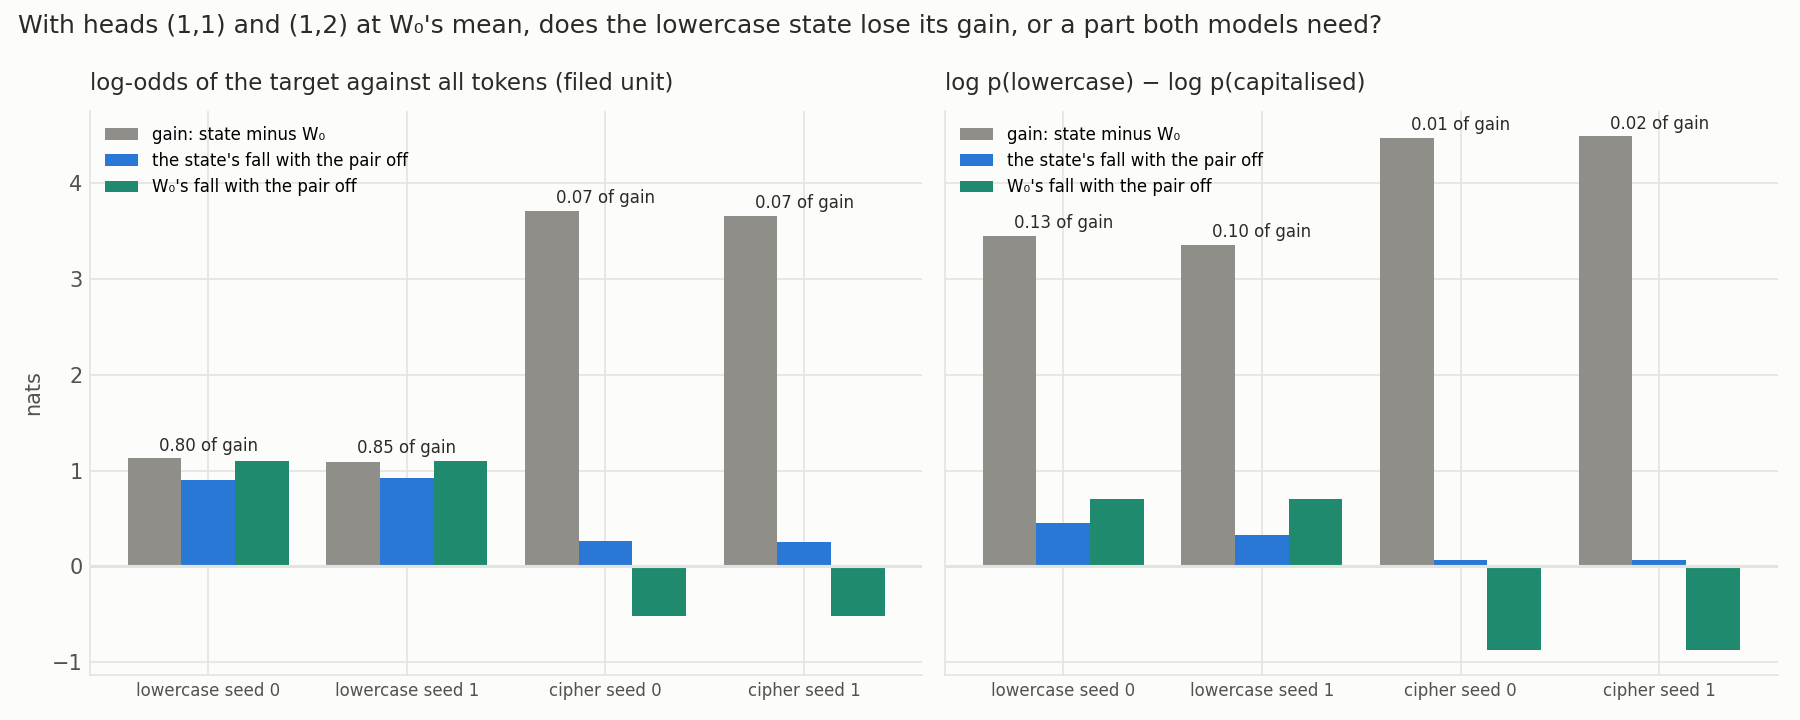

In [6]:
display(Image(FIG / "lowercase.png", width=1000))


**Reading it.** It is a part both models need, and whether that counts as located is the user's call. With heads (1,1) and (1,2) at W₀'s mean, the lowercase state falls 0.90 and 0.93 nats, 0.80 and 0.85 of its gain. The cipher state falls only 0.07 of its own. That clears the filed rule on both seeds, against our lean. But W₀ falls 1.10 nats with the same pair off, more than the state does. In the lowercase-against-capitalised unit the state loses only 0.10 to 0.13 of its gain, while W₀ loses 0.70 nats. The rule in the state's own terms says located; a rule on the net gain says the pair is something lowercase continuation needs in both models. We report both and pick neither. No single head clears the bar: the best, (1,1), takes 0.44 and 0.45.


## What we learned

For baseline-lead's table, only removal at head grain has passed a known answer, and only on narrow copying. Copy is located at (2,4) and the pair (2,3)+(2,4); the lookup and the cipher have no located part; lowercase is located in the state's own terms by a pair W₀ also needs. Reads that patch W₀'s outputs into the state report where the gain enters the output, which is block 3's MLP for both a reuse task and a new one, so they cannot nominate parts for the table. The write read says the copy update acts jointly across matrices, so no single matrix carries it. A new circuit built from old parts still reads as reuse, and the lowercase pair is that limit in practice.

## How compelling is the evidence

The planted edits and the copy control are exact or near it, with three seeds on copy and lookup and two on lowercase and cipher. Removal is blind to whether a part's job changed, only to whether the state needs it, and E62 had already pointed at (2,4), so the copy control has few teeth. The edge reads cover only E62's windows; lowercase, the cipher and the remaining 24-key and ladder tasks were not read with edges or with the third stage. The cross-faithfulness band rests on three seeds a side, read on pairs that differ by design.

## Surprises

- **The lowercase pair clears the located rule, against the lean**, and the original model needs it more than the state does.
- **The edge read did not single out the copying head.** Its edge to the output carries 0.08 to 0.11 of the copy gain. The rest flows through later MLPs.
- **Single-matrix reverts are tiny and far from additive.** On copy they sum to 0.16 to 0.23 of the gain, while all together remove all of it.
- **The hand-write check missed as filed, on a degenerate bar.** The planted edit's share with (2,4) off is 0.0003, and the lookup's largest share is negative, -0.005. Both are zero to the noise.
- **Cross-faithfulness separates by the filed rule**, which the job never computed because it stopped first.

## What next

1. The literature review that is running: which published locator passes a planted control on a fine-tune's change. A method that passes would take E97's last amendment; none would mean writing the table with removal alone.
2. The user's call on the lowercase pair: located in the state's own terms, or a shared part by the net rule.
3. Hand baseline-lead the table as it stands, with copy located, lookup and cipher not found, and lowercase both readings.


## Scorecard

The full table, with every stage-0 check, is in the report.

| Id | Claim | Rule | Read | Verdict |
|---|---|---|---|---|
| S0 plants | Plants read where made, 0 upstream | ±1e-4 | exact; floor 0.021 | held |
| S0 re-read | Gains re-read; all reverted gives 0 | within 0.02; at most 0.001 | at most 0.0009; 0 | held |
| S1 band | Copy removal at (2,4) | 0.56-0.65, reported | 0.649, 0.632, 0.559 | inside to two decimals |
| S1 lookup | Lookup removal at (2,4) | at most 0 | -0.005 to -0.009 | held |
| S1 control | Carry tops (2,4) on copy | every seed | mlp3 on all three | missed: tree's miss branch |
| S1 lean | Lookup's carry top an MLP in blocks 0-2 | lean | mlp3 | lean missed |
| S1 hand write | Plant with (2,4) off within lookup's share | at most lookup's largest | 0.0003 against -0.005 | missed; bar degenerate |
| S1 located | (2,4) and (2,3)+(2,4) on copy | a = 0.55 | 0.56-0.65; 0.78-0.88 | located |
| S2 lean | Lowercase: none at head grain | lean | (1,1)+(1,2) 0.80, 0.85; cipher 0.07 | lean missed: pair located |
| S2 floor | Inheritance under nominated shares | can nominate | 0.021 under 0.066 | held |
| S2 cipher | — | located rule | none | not located |
| A1 S0 | Edge read exact; plants | measured floor | under 3.5e-5; 1.0 | held |
| A1 sum | Single edges sum to carry | within 0.10 | mlp2 misses by 0.11 on 2 seeds | missed; check mis-specified |
| A1 joint | All an MLP's edges equal carry | within 1e-4 | all six | held |
| A1 top edge copy | (2,4) to output, lean | top on every seed | mlp3 to output | lean missed: tree stops |
| A1 top edge lookup | An MLP to output, lean | top | mlp3 to output | held |
| A1 (2,4) in circuit | In W₀'s copying circuit | yes | yes | held |
| A1 cross copy | At least 0.5, lean | — | 0.98, 0.99, 0.98 | held |
| A1 cross lookup | At most 0.2, lean | — | 0.25, 0.31, 0.28 | lean missed |
| A1 band | Copy above lookup | filed band rule | 0.98 against 0.32, by hand | separated, not computed by the job |

## Not run

- **E97's third stage**: rank-1, half-known, copy-24 and the cipher at 24 keys; ident32 against rand32; emoticon and two ladder rungs beside. The tree stopped it when carry missed (2,4).
- **The amendment's lowercase, cipher and third-stage edges.** The tree stopped them when the top edge on copy was not (2,4).
- **A capability map for lowercase**, deferred by the plan.
- **An edge-sum tolerance set from a measured additivity floor**, and the do-nothing state through the edge reads on a GPU; it ran only in the unit tests.
- **Neurons, directions, finer MLP units, edges restricted to positions, greedy circuit search, the TransformerLens package, anything on Qwen.**
- **An independent check.** No claim here is a headline yet.

## Departures from the literature

- **EAP-IG in our own code**, `src/commute/edges.py`, not Hanna et al.'s package, so that W₀'s outputs can serve as the corrupted run.
- **Midpoint steps** at $(k + 0.5)/8$ with 8 steps, E96's checked path, where the package takes $k/m$ and the paper 5 steps.
- **Circuits by top-n then pruning**, over a grid from 10 to 927 edges, the smallest with faithfulness at least 0.85; the paper also uses greedy search, not used here.
- **The gain path uses W₀'s outputs as the corrupted run, read in the state.** That is Prakash et al.'s cross-model patch at edge grain; Hanna et al. corrupt the inputs of one model.
- **Cross-faithfulness applies W₀'s circuit to a different model**, the state; Hanna et al. compare circuits of two tasks in one model.
- **Removal uses W₀'s means on the task's own windows**, not natural text as in E96, after E96's independent check.

## Provenance

Plans `reports/plans/2026-11-05_plan_e97-locator.md` and `reports/plans/2026-11-05_plan_e97-amend1.md`. Rules `experiments/locator_table/results/predictions.json`, `predictions_amend1.json`. Results `stage0.json`, `stage1.json`, `stage2.json`, `table.json`, `amend1_stage0.json`, `amend1_stage1.json`; logs `run.out`, `amend1.out`. Figures from `experiments/locator_table/plot.py`, no model. Jobs 52618 at about 24 minutes, 52619 stopped at once, 52646 with no stage to run, and 52785 at about 4 minutes; debug L40, $0. Report `reports/analyses/2026-11-05_analysis_e97-locator.md`.
